In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

np.random.seed(42)
tf.random.set_seed(42)
sns.set_theme(style="whitegrid")

DATA_URL = "https://raw.githubusercontent.com/caiks/AMES/master/train.csv"
EPOCHS = 100
BATCH_SIZE = 32

shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


,SalePrice
count,1460.0
mean,180921.0
std,79443.0
min,34900.0
25%,129975.0
50%,163000.0
75%,214000.0
max,755000.0


,missing
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81


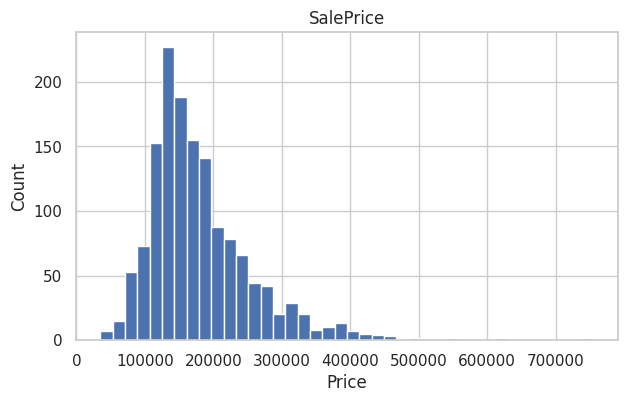

In [2]:
df = pd.read_csv(DATA_URL)
print("shape:", df.shape)
display(df.head())

display(df["SalePrice"].describe().round(0).to_frame("SalePrice"))

missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
display(missing.to_frame("missing"))

plt.figure(figsize=(7, 4))
plt.hist(df["SalePrice"], bins=40)
plt.title("SalePrice")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

In [3]:
data = df.drop(columns=["Id"]).copy()
y = data.pop("SalePrice")

X_train, X_temp, y_train, y_temp = train_test_split(
    data, y, test_size=0.30, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
num_fill = X_train[num_cols].median()

for frame in (X_train, X_val, X_test):
    frame[num_cols] = frame[num_cols].fillna(num_fill)
    frame[cat_cols] = frame[cat_cols].fillna("Missing")

X_train = pd.get_dummies(X_train, columns=cat_cols)
X_val = pd.get_dummies(X_val, columns=cat_cols)
X_test = pd.get_dummies(X_test, columns=cat_cols)
X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

scaler_x = StandardScaler()
X_train_s = scaler_x.fit_transform(X_train.to_numpy(dtype=np.float32))
X_val_s = scaler_x.transform(X_val.to_numpy(dtype=np.float32))
X_test_s = scaler_x.transform(X_test.to_numpy(dtype=np.float32))

scaler_y = StandardScaler()
y_train_s = scaler_y.fit_transform(y_train.to_numpy(dtype=np.float32).reshape(-1, 1))
y_val_s = scaler_y.transform(y_val.to_numpy(dtype=np.float32).reshape(-1, 1))

split_df = pd.DataFrame({
    "set": ["train", "validation", "test"],
    "samples": [len(y_train), len(y_val), len(y_test)],
})
display(split_df)
print("features after encoding:", X_train_s.shape[1])

,set,samples
0,train,1022
1,validation,219
2,test,219


features after encoding: 298


In [4]:
def build_mlp(hidden, name, input_dim):
    model = Sequential(name=name)
    model.add(Input(shape=(input_dim,)))
    for units in hidden:
        model.add(Dense(units, activation="relu"))
        model.add(Dropout(0.2))
    model.add(Dense(1))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss="mse",
        metrics=["mae"],
    )
    return model

configs = [
    {"name": "MLP-2", "hidden": [64, 32]},
    {"name": "MLP-3", "hidden": [128, 64, 32]},
    {"name": "MLP-4", "hidden": [256, 128, 64, 32]},
]

histories = {}
predictions = {}
param_counts = {}
input_dim = X_train_s.shape[1]

for cfg in configs:
    tf.keras.backend.clear_session()
    tf.random.set_seed(42)
    model = build_mlp(cfg["hidden"], cfg["name"], input_dim)
    model.summary()
    param_counts[cfg["name"]] = model.count_params()

    history = model.fit(
        X_train_s,
        y_train_s,
        validation_data=(X_val_s, y_val_s),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=0,
    )
    histories[cfg["name"]] = {k: list(v) for k, v in history.history.items()}
    pred_s = model.predict(X_test_s, verbose=0)
    predictions[cfg["name"]] = scaler_y.inverse_transform(pred_s).ravel()
    print("trained:", cfg["name"])

Model: "MLP-2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        19,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,249 (83.00 KB)

 Trainable params: 21,249 (83.00 KB)

 Non-trainable params: 0 (0.00 B)

trained: MLP-2


... (8 outputs left out)

 Total params: 119,809 (468.00 KB)

 Trainable params: 119,809 (468.00 KB)

 Non-trainable params: 0 (0.00 B)

trained: MLP-4


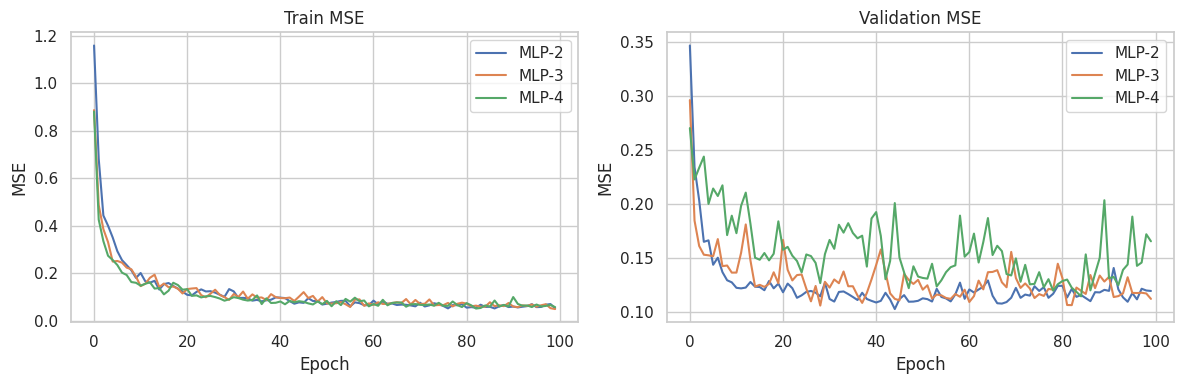

In [5]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
for name, hist in histories.items():
    plt.plot(hist["loss"], label=name)
plt.title("Train MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()

plt.subplot(1, 2, 2)
for name, hist in histories.items():
    plt.plot(hist["val_loss"], label=name)
plt.title("Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()

plt.tight_layout()
plt.show()

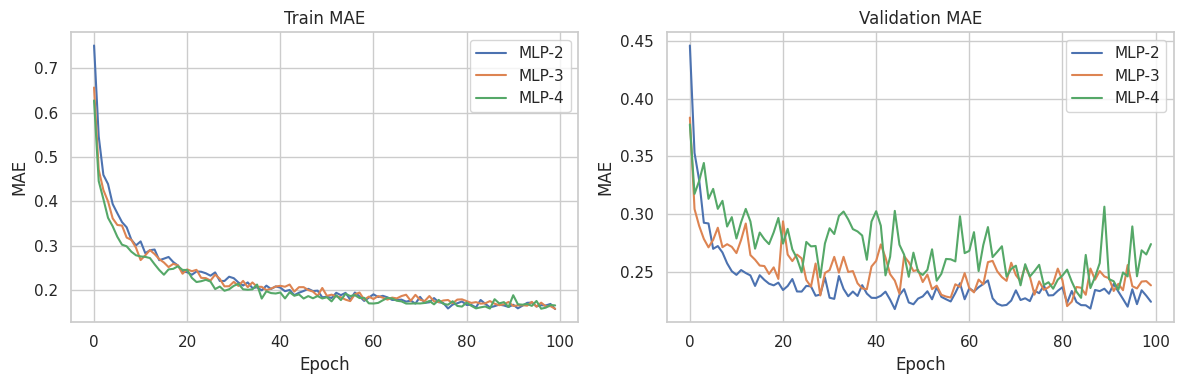

In [6]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
for name, hist in histories.items():
    plt.plot(hist["mae"], label=name)
plt.title("Train MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()

plt.subplot(1, 2, 2)
for name, hist in histories.items():
    plt.plot(hist["val_mae"], label=name)
plt.title("Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()

plt.tight_layout()
plt.show()

In [7]:
y_test_arr = y_test.to_numpy(dtype=np.float32)
rows = []

for name, y_pred in predictions.items():
    mse = mean_squared_error(y_test_arr, y_pred)
    rows.append({
        "Model": name,
        "Hidden layers": int(name.split("-")[1]),
        "Parameters": param_counts[name],
        "Val MSE": histories[name]["val_loss"][-1],
        "Test MSE": mse,
        "Test RMSE": np.sqrt(mse),
        "Test MAE": mean_absolute_error(y_test_arr, y_pred),
        "R2": r2_score(y_test_arr, y_pred),
    })

results = pd.DataFrame(rows).set_index("Model")
pretty = results.copy()
for col in ["Test MSE", "Test RMSE", "Test MAE"]:
    pretty[col] = pretty[col].round(0)
pretty["Val MSE"] = results["Val MSE"].round(4)
pretty["R2"] = results["R2"].round(4)
display(pretty)

,Hidden layers,Parameters,Val MSE,Test MSE,Test RMSE,Test MAE,R2
Model,,,,,,,
MLP-2,2,21249,0.1197,8.779149e+08,29630.0,18505.0,0.8846
MLP-3,3,48641,0.1124,1.126983e+09,33571.0,21192.0,0.8519
MLP-4,4,119809,0.1656,1.696777e+09,41192.0,22801.0,0.7770


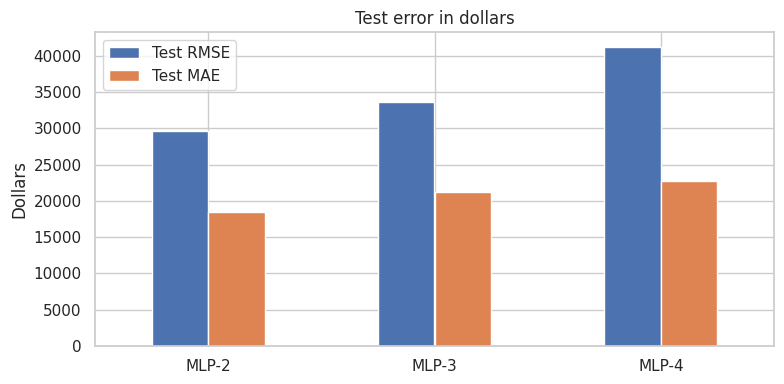

In [8]:
ax = results[["Test RMSE", "Test MAE"]].plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_title("Test error in dollars")
ax.set_ylabel("Dollars")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

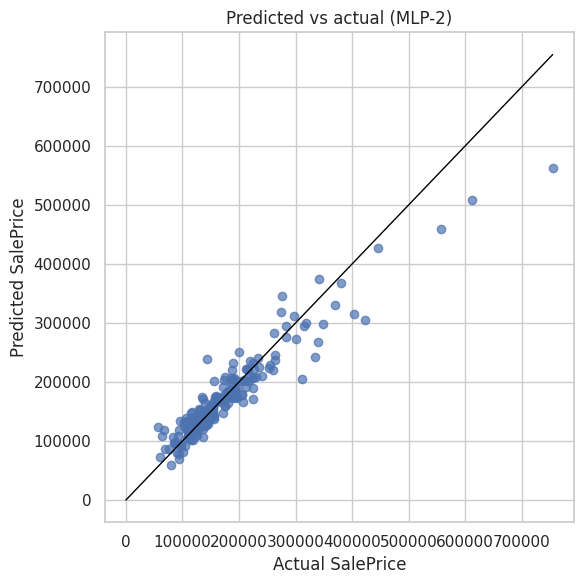

MLP-2


,Hidden layers,Parameters,Val MSE,Test MSE,Test RMSE,Test MAE,R2
Model,,,,,,,
MLP-2,2,21249,0.1197,877914944.0,29630.0,18505.0,0.8846


In [9]:
best = results["Test RMSE"].idxmin()
y_best = predictions[best]

plt.figure(figsize=(6, 6))
plt.scatter(y_test_arr, y_best, alpha=0.7)
limit = max(y_test_arr.max(), y_best.max())
plt.plot([0, limit], [0, limit], color="black", linewidth=1)
plt.title(f"Predicted vs actual ({best})")
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.tight_layout()
plt.show()

print(best)
display(pretty.loc[[best]])